# 1. ViT(Vision Transformer)
- ViT(Vision Transformer)는 이미지를 일정 크기의 패치(예: 16×16)로 나눈 뒤 각 패치를 임베딩 벡터로 투영해 토큰 시퀀스로 만들고, 여기에 위치 임베딩을 더해 트랜스포머 인코더(Multi-head Self-attention+FFN)로 처리하여 분류 등의 다운스트림 작업을 수행하는 모델입니다. 
- 분류의 경우 BERT처럼 맨 앞에 [CLS] 토큰을 두고 그 출력으로 최종 예측을 합니다. 
- CNN이 지역적 합성곱과 계층적 다운샘플링으로 전역 정보를 “깊이”에서 얻게 되는 반면, ViT는 자기어텐션으로 처음부터 전역 관계를 직접 학습하는 것이 특징입니다. 
- 충분한 데이터와 적절한 사전학습·증강이 있을 때 스케일이 클수록 성능이 잘 향상되지만, 어텐션의 계산량이 토큰 수 제곱(O(N²))에 비례해 해상도가 높거나 패치가 너무 작으면 비용이 크게 늘 수 있습니다.

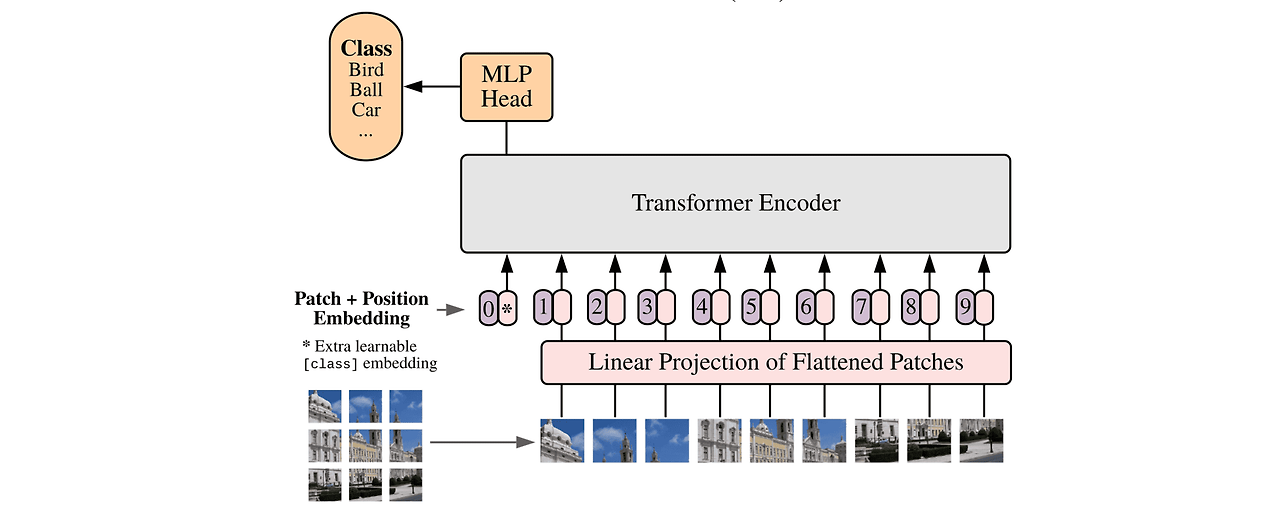

> NLP Transformer에서 단어(Token)가 들어가던 자리에 ViT에서는 이미지 patch token이 들어간다고 생각하면 됨.

1. NLP Transformer
    - 문장을 Token으로 분리
    - Token ID > Embedding
    - [CLS] Token
    - Position Embedding
    - Multi-Head Self-Attention 
    - FFN/MLP(Multi-Layer Perceptron)
    - 문장 분류

2. Vision Transfomer (ViT)
    - 이미지를 Patch로 분리
    - Patch > Linear Projection
    - [CLS] Token
    - Position Embedding
    - Multi-Head Self-Attention
    - FFN/MLP(Multi-Layer Perceptron)
    - 이미지 분류

- 이미지가 (3, 224, 224)이고 patch 크기가 16*16이면 한 변에 224/16 = 14개의 patch가 생김
- patch 수는 14*14 = 196개이고 [CLS] Token까지 추가하면 Transformer가 받는 sequence 길이는 197
- NLP의 Self-Attention과 계산 원리는 같음 > 각 patch가 Query, Key, Value를 만들고 다른 모든 patch와의 관계를 계산
- NLP와 ViT의 차이는 토큰의 출처가 글자인가, 이미지 조각인가의 차이

In [1]:
from pathlib import Path
import json
import random
import math
import time
import os

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


In [2]:
rng = np.random.default_rng(SEED)
image = rng.random((8,8,3), dtype=np.float32)

patch_size = 4
h, w, c = image.shape

# (H, W, C)
# (패치 세로 개수, patch_h, 패치 가로 개수, patch_w, C)
patches = image.reshape(h // patch_size, patch_size, w // patch_size, patch_size, c)

# patch의 위치가 앞쪽 차원에 오도록 
patches = patches.transpose(0, 2, 1, 3, 4)

# (총 patch 수, patch_h, patch_w, C)
patches = patches.reshape(-1, patch_size, patch_size, c)

print("원본 이미지: ", image.shape)
print("patches: ", patches.shape)

원본 이미지:  (8, 8, 3)
patches:  (4, 4, 4, 3)


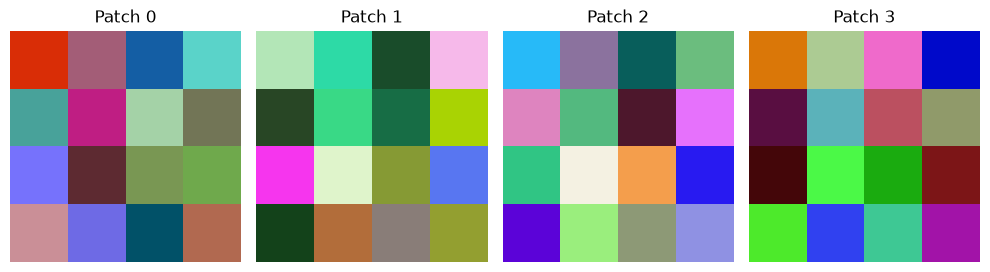

In [3]:
fig, axes = plt.subplots(1, len(patches), figsize=(10, 3))

for i, ax in enumerate(axes):
    ax.imshow(patches[i])
    ax.set_title(f"Patch {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Conv2d가 Patch Embedding이 되는 이유
- kernel_size=16, stride=16인 convolution은 서로 겹치지 않는 16*16 영역을 한 번씩 확인
- 출력 channel을 embed_dim으로 설정하면 각 patch를 embed_dim차원의 vector로 바꾸는 효과가 나게됨
- Patch 자르기 > Flatten > Linear == Conv2d(kernel=patch_size, stride=patch_size)

In [4]:
class PatchEmbedding(nn.Module):
    def __init__(self, patch_size=4, in_channels=3, embed_dim=32):
        super().__init__()
        self.patch_size = patch_size

        # 4×4 영역을 4칸씩 이동하며 처리 → 패치가 겹치지 않음
        # 각 패치의 RGB 픽셀을 학습 가능한 가중치로 32개 값으로 변환
        self.proj = nn.Conv2d(
            in_channels, 
            embed_dim, 
            kernel_size=patch_size, 
            stride=patch_size
        )

    # 순전파
    def forward(self, x):
        # input: (batch, channel, H, W)
        # 예: (1, 3, 8, 8)

        x = self.proj(x)
        # (1, 32, 2, 2)
        # patch 위치가 세로 2개 × 가로 2개이며, 위치마다 특징값 32개

        x = x.flatten(2)
        # (1, 32, 4)
        # 2번 축부터 끝까지 합침: 패치 위치 2×2 → 4개

        x = x.transpose(1, 2)
        # (1, 4, 32)
        # 패치 수와 특징 차원의 순서를 교환
        # Transformer가 받을 (배치, 토큰 수, 임베딩 차원) 형태

        return x

In [5]:
sample = torch.from_numpy(image).permute(2, 0, 1).unsqueeze(0)
patch_embed = PatchEmbedding(patch_size=4, in_channels=3, embed_dim=32)
tokens = patch_embed(sample)
print("Input: ", sample.shape)
print("Token: ", tokens.shape)

Input:  torch.Size([1, 3, 8, 8])
Token:  torch.Size([1, 4, 32])


### [CLS] Token과 Position Embedding
- Self-Attention 자체에는 순서나 위치 개념이 없음
- patch가 이미지의 어느 위치에서 왔는지 알려주는 Position Embedding이 필요
- [CLS] token은 NLP의 BERT에서 사용하던 방식과 매우 유사
- 모든 patch와 attention을 주고 받으면서 이미지 전체를 대표하는 표현으로 학습되고, 마지막에 이 token을 classification head에 넣어줌
- 참고로 최근 vision backbone은 [CLS] 하나만 사용하는 방식 외에도 global average pooling, register token, 상대/회전 위치 표현 등 여러 변형을 사용 > 원조 ViT 구조를 이해하기 위한 방법을 사용

In [6]:
# B (Batch): 이미지 개수
# N (Number of patches): 이미지 한 장의 패치 수 → 현재 4개
# D (Dimension): 각 패치를 표현하는 특징 벡터의 차원 → 현재 32
B, N, D = tokens.shape

# 모든 이미지에서 공통으로 사용하는 학습 가능한 CLS 벡터
# 아직 이미지 정보가 들어 있지 않으며, Transformer를 거치면서 정보를 모음
cls_token = nn.Parameter(torch.zeros(1, 1, D))

# CLS 1개 + 패치 N개의 위치마다 학습 가능한 위치 벡터를 준비
# 현재 shape: (1, 5, 32)
pos_embed = nn.Parameter(torch.zeros(1, N + 1, D))

# 작은 랜덤값으로 초기화하며, 이후 학습 과정에서 값이 갱신됨
nn.init.trunc_normal_(cls_token, std=0.02)
nn.init.trunc_normal_(pos_embed, std=0.02)

# expand: CLS를 배치의 각 이미지에 하나씩 사용하도록 확장
# -1: 해당 차원의 크기를 그대로 유지
# 이미지 2장이라면: CLS (1, 1, 32) → (2, 1, 32)
# 같은 CLS 파라미터를 공유하며, 이미지마다 별도의 파라미터를 만드는 것은 아님
#
# cat(dim=1): 토큰 축으로 CLS를 패치 토큰 앞에 붙임
# (2, 1, 32) + (2, 4, 32) → (2, 5, 32)
x = torch.cat([cls_token.expand(B, -1, -1), tokens], dim=1)

# 각 토큰에 해당 위치의 벡터를 원소별로 더함
# pos_embed의 첫 번째 차원 1이 B로 브로드캐스팅되어 모든 이미지에 적용됨
# 덧셈이므로 토큰 수와 특징 차원은 그대로: (B, N + 1, D)
x = x + pos_embed

print('Patch token 수: ', N)
print('CLS 추가 후: ', x.shape)

Patch token 수:  4
CLS 추가 후:  torch.Size([1, 5, 32])


### Transformer Encoder에 넣기

In [7]:
'''
입력 > LayerNorm > Multi-Head Self-Attention > FFN > 출력

D: 차원
nhead: Multi-Head Attention의 Head를 4개 사용 > 서로 다른 관계를 학습할 기회
dim_feedforward: 각 Token의 표현을 더 풍부하게 변환하는 역할
batch_first: (B, N, D)
norm_first: Layer Norm을 Attention과 FFN보다 먼저 할 것인지를 설정
'''

# layer 설정
encoder_layer = nn.TransformerEncoderLayer(
    d_model=D, nhead=4, dim_feedforward=D*4, dropout=0.1, 
    activation="gelu", batch_first=True, norm_first=True
)

# encoder에 layer x 2 넣기
# norm=nn.LayerNorm(D): 최종 출력에 LayerNorm을 한 번 더 적용
encoder = nn.TransformerEncoder(encoder_layer, num_layers=2, norm=nn.LayerNorm(D))

z = encoder(x)
classifier = nn.Linear(D, 10)
logits = classifier(z[:, 0])

print("Encoder 출력: ", z.shape)
print("분류 logits: ", logits.shape)
print("예측 class: ", logits.argmax(dim=1).item())

Encoder 출력:  torch.Size([1, 5, 32])
분류 logits:  torch.Size([1, 10])
예측 class:  3


C:\Users\kesgo\AppData\Local\Temp\ipykernel_33572\1323643014.py:19: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  encoder = nn.TransformerEncoder(encoder_layer, num_layers=2, norm=nn.LayerNorm(D))


# 2. 번호판 분류하기

In [8]:
DATA_ROOT = Path("./data/ViT")

ANNOTATION_PATH = DATA_ROOT / "annotations.json"
IMAGE_DIR = DATA_ROOT / "images"
MODEL_DIR = Path("./vit_train_results")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_ROOT       :", DATA_ROOT.resolve())
print("ANNOTATION_PATH :", ANNOTATION_PATH.resolve())
print("IMAGE_DIR       :", IMAGE_DIR.resolve())

DATA_ROOT       : C:\DEV\AIML\4_MULTIMODAL\data\ViT
ANNOTATION_PATH : C:\DEV\AIML\4_MULTIMODAL\data\ViT\annotations.json
IMAGE_DIR       : C:\DEV\AIML\4_MULTIMODAL\data\ViT\images


In [9]:
with ANNOTATION_PATH.open("r", encoding="utf-8") as f:
    annotations = json.load(f)

print("전체 데이터 개수:", len(annotations))
print("첫 annotation:", annotations[0])

전체 데이터 개수: 36828
첫 annotation: {'filename': '21구2298.jpg', 'labels': '2298'}


```
하나의 이미지에서 4개의 숫자를 각각 예측하는 Multi-Head Classification 문제
- 예) 정답이 "1234" Head1: 1, Head2: 2, Head3: 3, Head4: 4
- Transformer backbone은 하나를 공유하고, 마지막 classification head만 4개로 나눔
- Transformer 관점에서는 공통 encoder 표현을 여러 task head가 공유하는 multi-task learning과 비슷함
```

In [10]:
from collections import Counter

# 각 자리의 숫자 등장 횟수를 저장할 Counter 4개 생성
# Counter는 없는 숫자를 조회하면 0으로 취급하므로 바로 += 1 가능
# [첫째 자리 집계, 둘째 자리 집계, 셋째 자리 집계, 넷째 자리 집계]
position_counts = [Counter() for _ in range(4)]

# 전체 annotation을 하나씩 확인
for item in annotations:

    # labels가 [1, 2, 3, 4]라면:
    # (pos, label) → (0, 1), (1, 2), (2, 3), (3, 4)
    for pos, label in enumerate(item["labels"]):

        # 해당 자리에서 해당 숫자의 등장 횟수를 1 증가
        # int(label): "1" 같은 문자열도 정수 1로 통일
        position_counts[pos][int(label)] += 1

# 출력할 때는 사람이 읽기 쉽게 자리 번호를 1부터 표시
# start=1은 출력용 pos에만 적용되며 리스트 구조는 바뀌지 않음
for pos, counts in enumerate(position_counts, start=1):
    print(f"\n{pos}번째 자리 분포")

    # items(): (숫자, 등장 횟수) 쌍을 가져옴
    # sorted(): 숫자를 기준으로 오름차순 정렬
    # dict(): 정렬한 결과를 딕셔너리 형태로 출력
    print(dict(sorted(counts.items())))


1번째 자리 분포
{0: 3978, 1: 4091, 2: 3617, 3: 3505, 4: 3611, 5: 4056, 6: 4110, 7: 3340, 8: 3535, 9: 2985}

2번째 자리 분포
{0: 3426, 1: 3876, 2: 3793, 3: 3769, 4: 3644, 5: 3762, 6: 3698, 7: 3683, 8: 3645, 9: 3532}

3번째 자리 분포
{0: 3647, 1: 3663, 2: 3762, 3: 3597, 4: 3550, 5: 3948, 6: 3789, 7: 3631, 8: 3623, 9: 3618}

4번째 자리 분포
{0: 3594, 1: 3755, 2: 3658, 3: 3694, 4: 3440, 5: 3681, 6: 3595, 7: 3866, 8: 3785, 9: 3760}


In [11]:
# 데이터 분할 Train/Val

indices = np.arange(len(annotations))
rng = np.random.default_rng(SEED)
rng.shuffle(indices)

split = int(len(indices) * 0.9)
train_idx = indices[:split]
val_idx = indices[split:]

train_annot = [annotations[i] for i in train_idx]
val_annot = [annotations[i] for i in val_idx]

print("Train:", len(train_annot))
print("Val  :", len(val_annot))

Train: 33145
Val  : 3683


In [12]:
# albumentations: 이미지 전처리와 데이터 증강 라이브러리
# ToTensorV2: 파이썬 Tensor 변환, 
#   OpenCV이미지 Shape: (H, W, C), 
#   PyTorch 모델이 원하는 형태: (C, H, W)

import albumentations as A
from albumentations.pytorch import ToTensorV2

IMAGE_SIZE = 224  # 모델에 입력할 최종 이미지 크기: 224×224

# 학습용: 무작위 증강으로 다양한 모양의 이미지를 학습하게 함
# Compose: 아래 변환을 위에서부터 순서대로 적용
train_transform = A.Compose([
    # 60% 확률로 확대/축소, 이동, 회전, 기울이기를 적용
    # 숫자가 잘리거나 다른 숫자로 보일 정도로 변형하지 않도록 범위를 작게 설정
    A.Affine(
        scale=(0.92, 1.08),               # 원본 크기의 92~108%로 조절
        translate_percent=(-0.04, 0.04),  # 가로·세로 방향으로 크기의 ±4% 범위 이동
        rotate=(-8, 8),                   # -8°~8°도 회전
        shear=(-3, 3),                    # -3°~3°도 범위로 기울이기
        border_mode=0,                    # 변형으로 생긴 빈 영역을 상수값으로 채움
        p=0.6,                            # 이 변환을 적용할 확률 (60%)
    ),

    # 30% 확률로 밝기와 대비를 무작위 변경
    # 촬영 시 조명이나 명암이 달라지는 상황에 대비
    A.RandomBrightnessContrast(
        brightness_limit=0.15,  # 기본 설정에서 최대 픽셀값 기준 ±15% 밝기 조절
        contrast_limit=0.15,    # 대비를 약 0.85~1.15배 범위로 조절
        p=0.3,                  # 30% 확률
    ),

    # 가로·세로 비율을 유지하면서 긴 변을 224픽셀로 맞춤
    # 예: (높이 100, 너비 200) → (112, 224)
    A.LongestMaxSize(max_size=IMAGE_SIZE),

    # 짧은 변의 부족한 부분을 채워 최종 크기를 224×224로 맞춤
    # 이미지를 늘려서 찌그러뜨리지 않고 여백을 추가하는 방식
    A.PadIfNeeded(
        min_height=IMAGE_SIZE,
        min_width=IMAGE_SIZE,
        border_mode=0,  # 여백을 상수값으로 채움
    ),

    # RGB 채널별로 픽셀값을 정규화
    # 기본 설정의 계산: (픽셀값 / 255.0 - mean) / std
    # 아래 mean과 std는 ImageNet에서 널리 사용하는 값
    # 모델 내부의 LayerNorm과는 별개인 입력 이미지 전처리
    A.Normalize(
        mean=(0.485, 0.456, 0.406),  # R, G, B 채널별 평균
        std=(0.229, 0.224, 0.225),  # R, G, B 채널별 표준편차
    ),

    # NumPy 배열 (H, W, C) → PyTorch Tensor (C, H, W)
    # 여기서는 (224, 224, 3) → (3, 224, 224)
    # 배치 차원은 이후 DataLoader가 추가
    ToTensorV2(),
])

# 검증용: 일정한 조건에서 성능을 평가하기 위해 무작위 증강을 제외
# 크기 조절, 패딩, 정규화 방식은 학습용과 동일하게 유지
val_transform = A.Compose([
    # 비율을 유지하면서 긴 변을 224픽셀로 맞춤
    A.LongestMaxSize(max_size=IMAGE_SIZE),

    # 부족한 부분에 여백을 추가하여 224×224로 맞춤
    A.PadIfNeeded(
        min_height=IMAGE_SIZE,
        min_width=IMAGE_SIZE,
        border_mode=0,
    ),

    # 학습 때와 같은 기준으로 RGB 픽셀값 정규화
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),

    # 모델이 입력받는 (3, 224, 224) 형태의 Tensor로 변환
    ToTensorV2(),
])

c:\DEV\AIML\4_MULTIMODAL\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
# JSON annotation을 이용해 이미지와 정답을 하나씩 가져오는 Dataset
# Dataset을 상속하여 PyTorch DataLoader에서 사용할 수 있게 함
class JsonDataset(Dataset):
    def __init__(self, image_dir, annotations, transform=None):
        # 이미지가 저장된 폴더 경로
        # Path로 변환하면 / 연산자로 파일 경로를 연결할 수 있음
        self.image_dir = Path(image_dir)

        # 이미지 파일명과 정답 라벨이 들어 있는 annotation 목록
        self.annotations = annotations

        # 이미지 전처리 및 증강 함수
        # 전달하지 않으면 None → 원본 이미지를 그대로 반환
        self.transform = transform

        self.num_classes = 10  # # 각 자리에서 분류할 숫자는 0~9 >> 클래스 10개

    def __len__(self):
        # 데이터 전체 개수
        # len(dataset)을 호출하면 실행됨
        return len(self.annotations)

    def __getitem__(self, idx):
        # dataset[idx]를 호출하면 실행됨
        # DataLoader도 이 메서드를 이용해 데이터를 가져옴

        # idx번째 이미지의 파일명과 정답 정보를 가져옴
        item = self.annotations[idx]

        # 이미지 폴더와 파일명을 연결해 전체 경로 생성
        image_path = self.image_dir / item["filename"]

        # 이미지를 열고 RGB 3채널로 통일한 뒤 NumPy 배열로 변환
        # shape: (높이, 너비, 채널) = (H, W, 3)
        image = np.array(Image.open(image_path).convert("RGB"))

        # 네 자리 정답을 정수 Tensor로 변환
        # 예: ["1", "2", "3", "4"] → tensor([1, 2, 3, 4])
        # shape: (4,)
        # torch.long: CrossEntropyLoss의 클래스 인덱스 정답에 사용하는 자료형
        target = torch.tensor(
            [int(x) for x in item["labels"]],
            dtype=torch.long
        )

        # 전처리 함수가 전달된 경우에만 적용
        if self.transform is not None:
            # Albumentations는 image= 키워드로 이미지를 받으며,
            # 결과를 딕셔너리로 반환하므로 ["image"]로 변환된 이미지를 꺼냄
            # 앞서 정의한 transform은 ToTensorV2()까지 포함하므로
            # 최종 image는 (3, 224, 224) 형태의 Tensor가 됨
            image = self.transform(image=image)["image"]

        # 이미지 한 장과 해당 이미지의 네 자리 정답을 반환
        # 앞서 정의한 transform 적용 시:
        # image: (3, 224, 224), target: (4,)
        return image, target

In [14]:
train_dataset = JsonDataset(IMAGE_DIR, train_annot, train_transform)
val_dataset = JsonDataset(IMAGE_DIR, val_annot, val_transform)

NUM_WORKERS = 0 if os.name == "nt" else min(4, os.cpu_count() or 1)
BATCH_SIZE = 32

In [15]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)

images, targets = next(iter(train_loader))
print("images :", images.shape)
print("targets:", targets.shape)
print("예시 target:", targets[0])

images : torch.Size([32, 3, 224, 224])
targets: torch.Size([32, 4])
예시 target: tensor([1, 5, 6, 8])


```
pip install timm

모델: vit_small_patch16_224
    - ViT-Base 보다 가볍고 실습하기 좋음
    - 224*224 입력, 16*16 patch
    - pretrained를 활용하므로 적은 데이터에서도 일반 학습보다 유리함
```

In [16]:
# PyTorch에 비해 좀 더 최신모델(트렌디함)이 많다
import timm

In [17]:
MODEL_NAME = "vit_small_patch16_224"

In [18]:
# ViT로 이미지 특징을 추출하고, 각 자리의 숫자를 별도 분류기로 예측
class ViTMultiHeadClassifier(nn.Module):
    def __init__(
        self,
        num_classes=10,        # 각 자리의 선택지: 숫자 0~9
        num_heads_out=4,       # 예측할 자리 수: 네 자리 → 분류기 4개
        model_name=MODEL_NAME, # 사용할 timm 모델 이름
        pretrained=True,       # 사전학습된 가중치를 불러올지 여부
        head_dropout=0.2,      # 학습 시 head 입력 특징을 20% 확률로 0으로 만듦
    ):
        # nn.Module 초기화: 하위 계층과 파라미터를 관리할 수 있게 함
        super().__init__()

        # 공통 특징 추출기(backbone) 생성
        # num_classes=0: 기존 ImageNet classifier를 제거하고 클래스 점수 대신 feature 벡터 반환
        # 특징을 모으는 방식(CLS 또는 pooling 등)은 선택한 모델 설정에 따름
        self.backbone = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=0,
        )

        # backbone이 이미지 한 장을 표현하는 특징 벡터의 차원
        feature_dim = self.backbone.num_features

        # 각 자리를 담당하는 분류기 생성
        # ModuleList에 넣어야 각 head의 파라미터가 모델에 등록되어
        # 학습, 저장, .to(DEVICE) 적용 대상에 포함됨
        self.heads = nn.ModuleList([
            nn.Sequential(
                # 이미지별 특징 벡터의 feature_dim개 값을 정규화
                nn.LayerNorm(feature_dim),

                # 학습 시 일부 특징을 무작위로 0으로 만들어 과적합 완화
                # model.eval() 상태에서는 값을 제거하지 않음
                nn.Dropout(head_dropout),

                # 특징 벡터 → 숫자 0~9에 대한 점수 10개
                # 출력은 확률이 아닌 logits이며 음수도 가능
                nn.Linear(feature_dim, num_classes),
            )
            for _ in range(num_heads_out)
            # 반복할 때마다 별도 계층을 생성하므로 head별 가중치가 다름
        ])

    def forward(self, x):
        # 입력 이미지: (B, 3, IMAGE_SIZE, IMAGE_SIZE)
        # 공통 backbone을 한 번 통과하여 이미지마다 특징 벡터 하나 추출
        features = self.backbone(x)  # (B, feature_dim)

        # 같은 특징 벡터를 모든 head에 전달
        # 각 head가 자신이 담당하는 자리의 숫자 점수를 계산
        # 반환값: (B, 10) Tensor 4개가 들어 있는 리스트
        return [head(features) for head in self.heads]


# 모델 생성 후 사용할 장치(GPU 또는 CPU 등)로 이동
model = ViTMultiHeadClassifier().to(DEVICE)

In [19]:
model

ViTMultiHeadClassifier(
  (backbone): VisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      (norm): Identity()
    )
    (pos_drop): Dropout(p=0.0, inplace=False)
    (patch_drop): Identity()
    (norm_pre): Identity()
    (blocks): Sequential(
      (0): Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (q_norm): Identity()
          (k_norm): Identity()
          (attn_drop): Dropout(p=0.0, inplace=False)
          (norm): Identity()
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (ls1): Identity()
        (drop_path1): Identity()
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True, bias=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=384, out_fea

In [20]:
# 출력 모양을 확인하기 위한 가짜 이미지 2장
# 실제 이미지가 아닌 표준정규분포에서 뽑은 임의의 값
sample_input = torch.randn(
    2, 3, IMAGE_SIZE, IMAGE_SIZE,
    device=DEVICE,
)

# 기울기를 기록하지 않아 이 확인 과정의 메모리 사용을 줄임
# 주의: no_grad()는 평가 모드 전환이 아니므로 Dropout은 여전히 작동
# 평가 동작으로 확인하려면 별도로 model.eval() 호출이 필요
with torch.no_grad():
    sample_outputs = model(sample_input)

# 리스트에 담긴 분류 결과 개수: 기본값 4개
print("Head 개수:", len(sample_outputs))

# 각 head는 이미지 2장에 대해 숫자 10개의 점수를 출력
# Head 1~4 모두 torch.Size([2, 10])
for i, out in enumerate(sample_outputs, start=1):
    print(f"Head {i}:", out.shape)

Head 개수: 4
Head 1: torch.Size([2, 10])
Head 2: torch.Size([2, 10])
Head 3: torch.Size([2, 10])
Head 4: torch.Size([2, 10])


In [21]:
# 전체 학습 데이터를 10번 반복해서 학습
EPOCHS = 10

# 학습률: 가중치를 한 번 갱신할 때 이동하는 크기를 조절
# 3e-5 = 0.00003 → 사전학습된 가중치를 조금씩 조정
LR = 3e-5

# 가중치가 지나치게 커지는 것을 억제하는 강도
# AdamW에서는 학습률과 함께 적용되며, 가중치를 매번 5% 줄인다는 뜻은 아님
WEIGHT_DECAY = 0.05

# 정답에만 확률 1을 주는 대신 일부를 모든 클래스에 나누는 label smoothing
# 과도한 확신을 줄여 일반화에 도움을 줄 수 있음
# 클래스 10개, smoothing=0.1인 경우:
# 정답: 0.9 + 0.1/10 = 0.91
# 나머지: 각각 0.1/10 = 0.01
# 정답을 직접 확률 벡터로 바꿀 필요 없이 정수 라벨을 그대로 전달
LABEL_SMOOTHING = 0.1
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

# AdamW: 기울기를 바탕으로 모델 가중치를 갱신하는 optimizer
# model.parameters(): backbone과 head 4개의 파라미터를 모두 전달
# 별도로 고정하지 않은 파라미터가 학습 대상이 됨
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)

# 학습이 진행될수록 학습률을 코사인 곡선 형태로 부드럽게 낮춤
# 초반에는 상대적으로 크게 조정하고, 후반에는 작게 조정
# scheduler의 cosine 감소 주기를 10번의 scheduler step으로 설정
# eta_min: LR을 최소 어디까지 낮출 것인지 설정
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,       # scheduler.step() 10회 동안 최저 학습률까지 감소
    eta_min=LR * 0.05, # 최저 학습률: 초기값의 5% = 0.0000015
)

# 위 설정에서 epoch 기준으로 학습률을 낮추려면
# 각 epoch의 학습이 끝난 뒤 scheduler.step()을 한 번 호출해야 함
# scheduler는 생성만으로 자동 실행되지 않음

### AMP(Ausotmatic Mixed Precision)
- GPU에서는 mixex precision을 사용하며 연산 속도를 높이고 GPU 메모리 사용량을 줄일 수 있음
- torch.amp.autocast & torch.amp.GradScaler를 사용
- 자동 혼합 정밀도
    - FP32(32비트 부동소수점): 정밀한 계산. 메모리를 더 많이 사용. 계산량이 큼
    - FP16(16비트 부동소수점): 낮은 정밀도. 메모리를 절약. 계산량이 적음

> 상황에 맞게 섞서 사용할 수 있는 기술이 Mixed Precision

In [22]:
use_amp = (DEVICE.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

print("AMP enabled:", use_amp)

AMP enabled: True


In [23]:
# 평가
# 평가 중에는 기울기를 계산하지 않음
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()  # 평가 모드: Dropout 비활성화

    total_loss = 0.0
    total_samples = 0
    correct_per_head = torch.zeros(4, dtype=torch.long)  # 자리별 정답 수
    exact_correct = 0  # 네 자리 모두 맞힌 이미지 수

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        # CUDA에서만 혼합 정밀도 사용
        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda"),
        ):
            outputs = model(images)

            # 각 자리의 손실을 구한 뒤 평균
            losses = [
                criterion(outputs[i], targets[:, i])
                for i in range(4)
            ]
            loss = torch.stack(losses).mean()

        # 배치 크기를 반영하여 손실 누적
        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        # 각 자리에서 점수가 가장 높은 숫자 선택 → (B, 4)
        preds = torch.stack(
            [out.argmax(dim=1) for out in outputs],
            dim=1
        )

        correct_matrix = preds.eq(targets)  # 자리별 정답 여부

        correct_per_head += correct_matrix.sum(dim=0).cpu()
        exact_correct += correct_matrix.all(dim=1).sum().item()

    # 자리별 정확도와 네 자리 완전 일치 정확도
    digit_acc = (correct_per_head.float() / total_samples).tolist()
    exact_acc = exact_correct / total_samples

    return {
        "loss": total_loss / total_samples,
        "digit_acc": digit_acc,
        "exact_acc": exact_acc,
    }

In [24]:
# 전체 학습 데이터를 한 번 학습하는 함수: 1 epoch
def train_one_epoch(model, loader, optimizer, criterion, scaler, device):
    model.train()  # 학습 모드: Dropout 활성화

    total_loss = 0.0
    total_samples = 0

    # 이미지와 네 자리 정답을 배치 단위로 가져옴
    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        # 이전 배치의 기울기 초기화
        # PyTorch는 기본적으로 기울기를 누적하므로 매번 초기화 필요
        optimizer.zero_grad(set_to_none=True)

        # CUDA에서만 FP16 기반 혼합 정밀도 사용
        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda"),
        ):
            # 각 자리의 예측 점수 반환: (B, 10) Tensor 4개
            outputs = model(images)

            # 각 자리의 예측과 해당 자리 정답으로 손실 계산
            # targets[:, i]: 모든 이미지의 i번째 자리 정답
            losses = [
                criterion(outputs[i], targets[:, i])
                for i in range(4)
            ]

            # 네 자리 손실의 평균을 최종 손실로 사용
            loss = torch.stack(losses).mean()

        # 손실을 확대하여 작은 기울기의 소실을 줄이고 역전파
        # 각 파라미터에 대한 기울기를 계산하며, 아직 가중치를 바꾸지는 않음
        scaler.scale(loss).backward()

        # clipping은 실제 기울기 크기를 기준으로 해야 하므로
        # GradScaler가 적용한 배율을 먼저 제거
        scaler.unscale_(optimizer)

        # 전체 기울기의 norm이 1.0을 넘으면 비례해서 축소
        # 기울기가 지나치게 커져 학습이 불안정해지는 현상을 완화
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # 기울기에 inf/NaN이 없으면 optimizer로 가중치 갱신
        # 문제가 있으면 해당 업데이트를 건너뜀
        scaler.step(optimizer)

        # 다음 배치에 사용할 기울기 확대 배율 조절
        scaler.update()

        # 배치 평균 손실에 이미지 수를 곱해 누적
        # 마지막 배치의 크기가 작아도 전체 평균에 올바르게 반영
        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    # 이번 epoch의 이미지당 평균 손실 반환
    return total_loss / total_samples

In [25]:
# 리턴받은 값들 저장하는 리스트
history = {
    "train_loss": [],
    "val_loss": [],
    "exact_acc": [],
    "digit_acc": [],
}

best_exact_acc = -1.0
best_path = MODEL_DIR / "best_vit_multihead.pth"

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    # epoch 한바퀴 돌때마다 실행될 함수
    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
        DEVICE,
    )

    # validation (모의고사)
    metrics = evaluate(
        model,
        val_loader,
        criterion,
        DEVICE,
    )

    scheduler.step()  # scheduler에 반영

    # 리턴된 값들 list에 append
    history["train_loss"].append(train_loss)
    history["val_loss"].append(metrics["loss"])
    history["exact_acc"].append(metrics["exact_acc"])
    history["digit_acc"].append(metrics["digit_acc"])

    digit_text = " | ".join(
        f"D{i+1}: {acc*100:6.2f}%"
        for i, acc in enumerate(metrics["digit_acc"])
    )

    print(
        f"[{epoch:02d}/{EPOCHS}] "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={metrics['loss']:.4f} | "
        f"{digit_text} | "
        f"Exact={metrics['exact_acc']*100:6.2f}% | "
        f"lr={optimizer.param_groups[0]['lr']:.2e} | "
        f"{time.time()-start:.1f}s"
    )

    if metrics["exact_acc"] > best_exact_acc:
        best_exact_acc = metrics["exact_acc"]

        # 저장할 값들
        torch.save({
            "epoch": epoch,
            "model_name": MODEL_NAME,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_exact_acc": best_exact_acc,
            "image_size": IMAGE_SIZE,
            "num_classes": 10,
            "num_heads_out": 4,
        }, best_path)

        print(f"  -> Best model 저장: {best_path}")

print(f"\nBest Exact Match Accuracy: {best_exact_acc*100:.2f}%")

[01/10] train_loss=1.4553 | val_loss=0.6821 | D1:  97.86% | D2:  94.38% | D3:  91.96% | D4:  95.60% | Exact= 84.09% | lr=2.93e-05 | 286.8s
  -> Best model 저장: vit_train_results\best_vit_multihead.pth
[02/10] train_loss=0.6209 | val_loss=0.5708 | D1:  98.91% | D2:  97.64% | D3:  96.88% | D4:  98.26% | Exact= 93.16% | lr=2.73e-05 | 209.7s
  -> Best model 저장: vit_train_results\best_vit_multihead.pth
[03/10] train_loss=0.5651 | val_loss=0.5486 | D1:  99.21% | D2:  98.29% | D3:  98.13% | D4:  98.48% | Exact= 95.25% | lr=2.41e-05 | 208.7s
  -> Best model 저장: vit_train_results\best_vit_multihead.pth
[04/10] train_loss=0.5475 | val_loss=0.5347 | D1:  99.21% | D2:  98.78% | D3:  99.16% | D4:  98.89% | Exact= 96.77% | lr=2.02e-05 | 209.0s
  -> Best model 저장: vit_train_results\best_vit_multihead.pth
[05/10] train_loss=0.5371 | val_loss=0.5289 | D1:  99.46% | D2:  99.08% | D3:  99.00% | D4:  98.94% | Exact= 97.15% | lr=1.57e-05 | 265.8s
  -> Best model 저장: vit_train_results\best_vit_multihead.pth


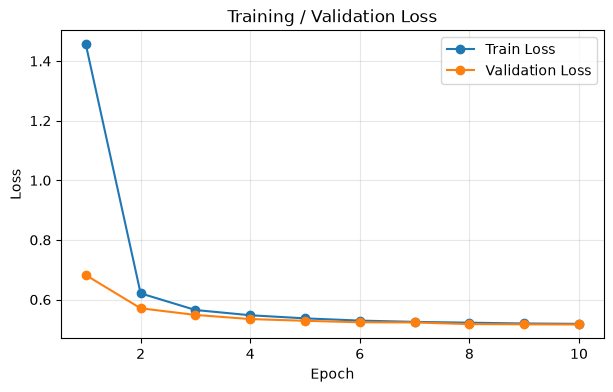

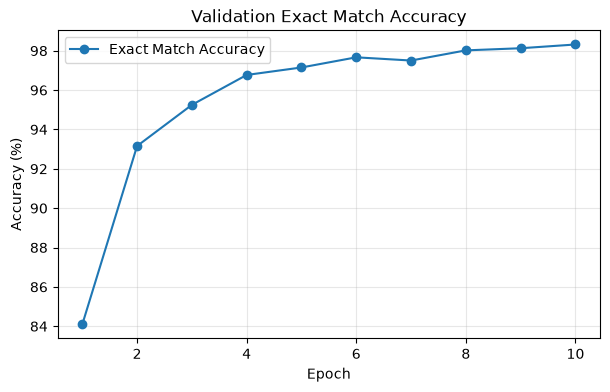

In [26]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training / Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(
    epochs,
    [x * 100 for x in history["exact_acc"]],
    marker="o",
    label="Exact Match Accuracy",
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Validation Exact Match Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
# 저장된 체크포인트 파일을 읽음
# 체크포인트: 모델 가중치, epoch, 정확도 등을 담아 저장한 딕셔너리
checkpoint = torch.load(
    best_path,             # 불러올 .pth 파일 경로
    map_location=DEVICE,   # 저장된 Tensor를 현재 사용할 장치로 불러옴
    weights_only=False,    # 가중치 외에 함께 저장한 정보도 불러옴
                           # 신뢰할 수 있는 체크포인트에만 사용
)

# 저장 당시와 같은 구조의 모델 생성
# 아직 저장된 학습 가중치가 적용된 상태는 아님
best_model = ViTMultiHeadClassifier(
    num_classes=checkpoint["num_classes"],      # 각 자리의 클래스 수: 10
    num_heads_out=checkpoint["num_heads_out"],  # 분류 head 수: 4
    model_name=checkpoint["model_name"],        # 저장 당시 backbone 이름

    # 사전학습 가중치를 별도로 가져오지 않음
    # 아래 코드에서 직접 학습해 저장한 가중치를 적용할 것이기 때문
    pretrained=False,
).to(DEVICE)

# 생성한 모델에 저장된 backbone과 head의 가중치를 적용
best_model.load_state_dict(checkpoint["model_state_dict"])

# 평가·예측 모드로 전환: Dropout 비활성화
# 기울기 기록까지 끄는 것은 아니므로 실제 예측에는 no_grad() 등을 별도 사용
best_model.eval()

# 이 모델을 저장한 시점의 epoch과 검증 정확도 출력
print("Best epoch:", checkpoint["epoch"])
print(
    "Best exact accuracy:",
    f"{checkpoint['best_exact_acc']*100:.2f}%"
)

Best epoch: 10
Best exact accuracy: 98.32%


In [28]:
# Tensor 이미지를 표시하거나 저장하기 쉬운 PIL 이미지로 변환
from torchvision.transforms.functional import to_pil_image

# 전처리에 사용했던 RGB 채널별 평균
# (3,) → (3, 1, 1)로 바꿔 이미지의 (3, H, W)에 맞춰 계산
# 각 채널의 모든 픽셀에 같은 평균값이 적용됨
IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

# 전처리에 사용했던 RGB 채널별 표준편차
IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


# 정규화된 이미지 Tensor (3, H, W)를 PIL 이미지로 변환
def tensor_to_pil(tensor):
    # 기울기 계산 연결을 끊고 CPU로 이동
    # 화면 표시용 변환이므로 학습 계산에 연결할 필요 없음
    tensor = tensor.detach().cpu()

    # 정규화의 역연산으로 픽셀값을 복원
    # 전처리: (픽셀값 - 평균) / 표준편차
    # 복원:   정규화된 값 * 표준편차 + 평균
    tensor = tensor * IMAGENET_STD + IMAGENET_MEAN

    # 0 미만은 0으로, 1 초과는 1로 제한
    # 실수형 이미지를 변환할 때 사용하는 픽셀 범위에 맞춤
    tensor = tensor.clamp(0, 1)

    # (3, H, W) Tensor를 PIL 이미지로 변환
    return to_pil_image(tensor)


# 숫자 목록이나 1차원 Tensor를 붙여서 문자열로 변환
def digits_to_text(x):
    # 예: [1, 2, 3, 4] → "1234"
    # int(v): 정수로 변환
    # str(...): 문자로 변환
    # "".join(...): 구분자 없이 이어 붙임
    return "".join(str(int(v)) for v in x)

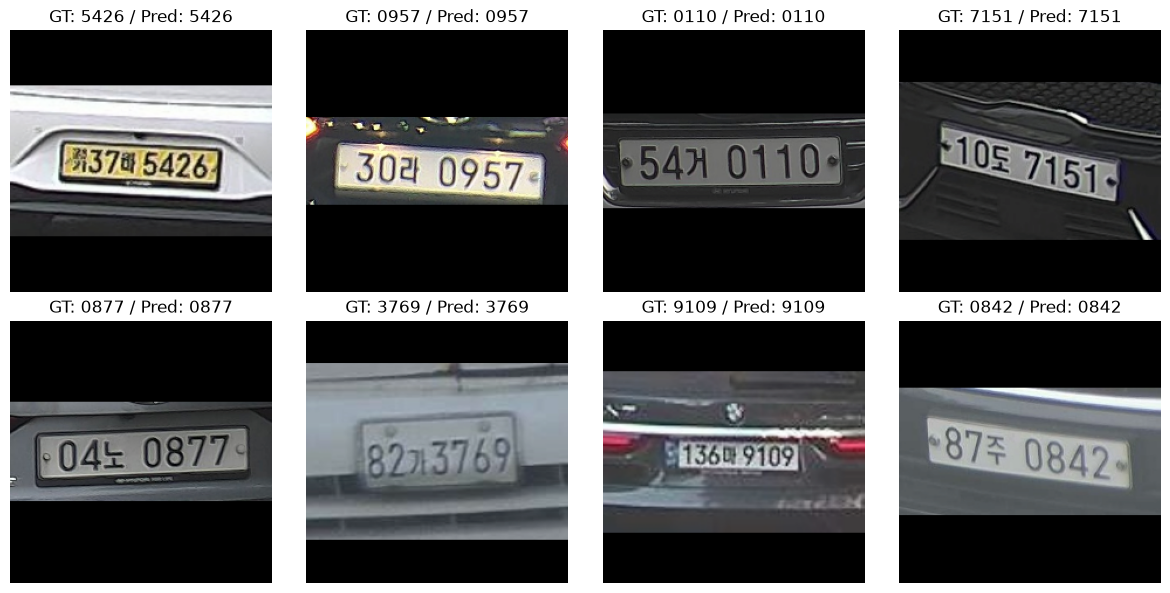

In [29]:
# 테스트
@torch.no_grad()
def show_predictions(model, loader, device, max_images=8):
    model.eval()

    shown = 0
    rows = math.ceil(max_images / 4)
    fig, axes = plt.subplots(rows, 4, figsize=(12, 3 * rows))
    axes = np.array(axes).reshape(-1)

    for images, targets in loader:
        images_device = images.to(device)

        outputs = model(images_device)
        preds = torch.stack(
            [out.argmax(dim=1) for out in outputs],
            dim=1
        ).cpu()

        for i in range(images.size(0)):
            if shown >= max_images:
                break

            true_text = digits_to_text(targets[i])
            pred_text = digits_to_text(preds[i])

            axes[shown].imshow(tensor_to_pil(images[i]))
            axes[shown].set_title(
                f"GT: {true_text} / Pred: {pred_text}"
            )
            axes[shown].axis("off")
            shown += 1

        if shown >= max_images:
            break

    for ax in axes[shown:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_predictions(best_model, val_loader, DEVICE)